<a href="https://colab.research.google.com/github/junaidatta123/Scientific-Projects/blob/main/Robot__Arm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
from my_functions import plot_robot_arm
from math import cos, sin
from matplotlib import pyplot as plt


In [30]:
# Input parameters
xp = [0.75, -1]       # target point
L1 = 1                # length of arm1
L2 = 1.5              # length of arm2
theta_0 = [2.5, 2.7]  # initial angles
tol = 0.01            # tolerance
alpha = 0.1           # learning rate
Niter = 1000          # max iterations

[-2.1572518285725253, 1.2395419644547012]


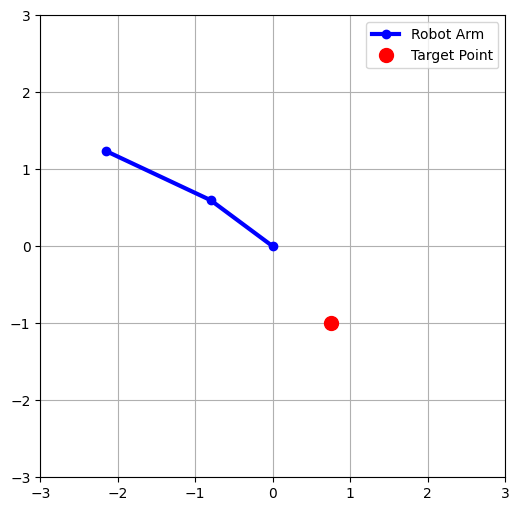

In [31]:
# Compute tip robot position
def robot_position(theta, L1, L2):
    theta1, theta2 = theta
    x = L1 * cos(theta1) + L2 * cos(theta2)
    y = L1 * sin(theta1) + L2 * sin(theta2)
    return [x, y]
# Plot robot arms
print(robot_position(theta_0, L1, L2))
plot_robot_arm(theta_0, xp, [L1, L2])


In [32]:
# Evaluation of J
def J(theta, xp, L1, L2):
    [x, y] = robot_position(theta, L1, L2)
    Jval = (x-xp[0])**2 + (y-xp[1])**2
    return Jval

print(J(theta_0, xp, L1, L2))


13.467661405291913


In [33]:
# Evaluation of Grad(J)
def grad_J(theta, xp, L1, L2):
    [x, y] = robot_position(theta, L1, L2)

    dx_dt1 = - L1 * sin(theta[0])
    dx_dt2 = - L2 * sin(theta[1])
    dy_dt1 =   L1 * cos(theta[0])
    dy_dt2 =   L2 * cos(theta[1])

    dJ_dx = 2*(x - xp[0])
    dJ_dy = 2*(y - xp[1])

    DJ_dt1 = dJ_dx*dx_dt1 + dJ_dy*dy_dt1
    DJ_dt2 = dJ_dx*dx_dt2 + dJ_dy*dy_dt2

    return [DJ_dt1, DJ_dt2]

Converged after 38 iterations.
Final angle combination: [0.6293180379169862, 4.687572633369985]
Final distance: 0.008380667670762636


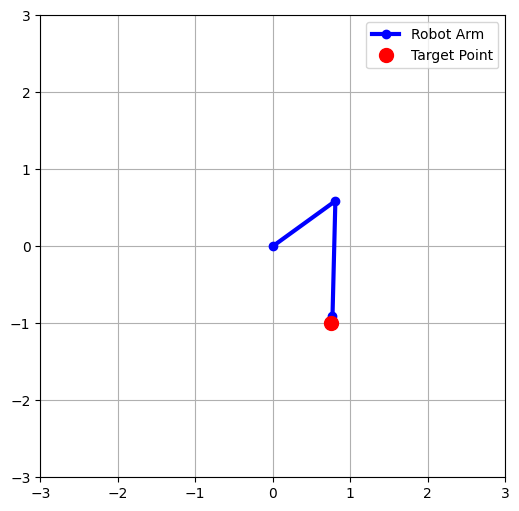

In [34]:
# Gradient Descent Method
i = 1
theta = theta_0
while i <= Niter:
    # Gradient of the objective function
    grad = grad_J(theta, xp, L1, L2)

    # Update theta with gradient
    theta[0] -= alpha * grad[0]
    theta[1] -= alpha * grad[1]

    # Compute the current distance
    Jval = J(theta, xp, L1, L2)

    # Check for convergence
    if Jval < tol:
        print(f"Converged after {i} iterations.")
        break

    i = i + 1

print("Final angle combination:", theta)
print("Final distance:", Jval)
plot_robot_arm(theta, xp, [L1, L2])

